# qPCR

In [1]:
import os
import sys
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg
import pandas as pd
%matplotlib inline
scripts = 'Scripts'
import seaborn as sns
sys.path.append(scripts)
import glob
import numpy as np
pd.options.mode.chained_assignment = None 
import scipy
from scipy import stats
from statsmodels.stats import multitest
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import math
dataDirectory = os.path.join('Results','qPCR')
sns.set_style("white")
sns.set_style("ticks")

figureDirectory = os.path.join('Figures','qCPR')
if not os.path.isdir(figureDirectory):
    os.mkdir(figureDirectory)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.size': 12, 'axes.titlesize':'medium',})
from scipy import stats
from statsmodels.stats import multitest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

MACS sorting for PB1 library to start.

/scratch/a5russell/job_12763203/ipykernel_919889/2150621162.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',
/scratch/a5russell/job_12763203/ipykernel_919889/2150621162.py:9: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',


9.656720751197907e-07


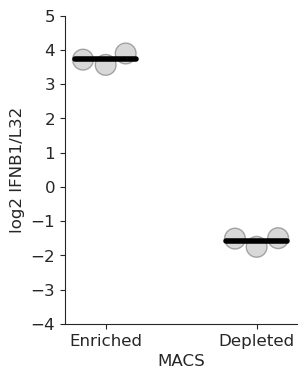

In [2]:
data = pd.read_csv(os.path.join(dataDirectory, 'PB1_lib_MACS.csv')).pivot_table(index=['MACS','replicate'], columns = 'target', aggfunc="mean", values='Cq').reset_index()
data['log2_IFNB1/L32'] = data.L32 - data['IFN-B']



fig, ax = plt.subplots(1,1, figsize=(3,4))
order = ['Enriched','Depleted']

sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',        
                dodge=False, linewidth=1, s=15,   zorder=5, order=order, ax=ax, alpha=0.3)

sns.despine()
a = plt.ylabel('log2 IFNB1/L32')
tstat, pval = stats.ttest_ind(data[data.MACS == 'Enriched']['log2_IFNB1/L32'], 
                                  data[data.MACS == 'Depleted']['log2_IFNB1/L32'], alternative='greater')
print(pval)

offset = 0
for position, MACS in enumerate(order):
    y = data[data.MACS == MACS]['log2_IFNB1/L32'].mean()
    plt.plot([position-0.2, position+0.2], [y, y], lw=4, c='k', zorder=9)

plt.ylim(-4,5)

plt.savefig(os.path.join(figureDirectory, 'PB1_lib_MACS.pdf'), bbox_inches="tight")

/scratch/a5russell/job_12763203/ipykernel_919889/298759022.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',
/scratch/a5russell/job_12763203/ipykernel_919889/298759022.py:9: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',


0.0002746156493375442


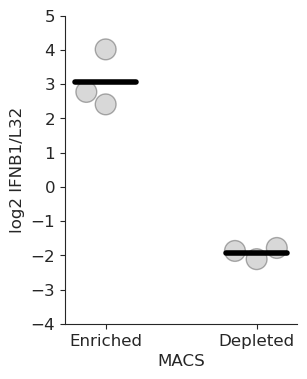

In [5]:
data = pd.read_csv(os.path.join(dataDirectory, 'PB2_lib_MACS.csv')).pivot_table(index=['MACS','replicate'], columns = 'target', aggfunc="mean", values='Cq').reset_index()
data['log2_IFNB1/L32'] = data.L32 - data['IFN-B']



fig, ax = plt.subplots(1,1, figsize=(3,4))
order = ['Enriched','Depleted']

sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',        
                dodge=False, linewidth=1, s=15,   zorder=5, order=order, ax=ax, alpha=0.3)

sns.despine()
a = plt.ylabel('log2 IFNB1/L32')
tstat, pval = stats.ttest_ind(data[data.MACS == 'Enriched']['log2_IFNB1/L32'], 
                                  data[data.MACS == 'Depleted']['log2_IFNB1/L32'], alternative='greater')
print(pval)

offset = 0
for position, MACS in enumerate(order):
    y = data[data.MACS == MACS]['log2_IFNB1/L32'].mean()
    plt.plot([position-0.2, position+0.2], [y, y], lw=4, c='k', zorder=9)

plt.ylim(-4,5)

plt.savefig(os.path.join(figureDirectory, 'PB2_lib_MACS.pdf'), bbox_inches="tight")

/scratch/a5russell/job_12763203/ipykernel_919889/4252905325.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',
/scratch/a5russell/job_12763203/ipykernel_919889/4252905325.py:9: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',


5.859221114061601e-07


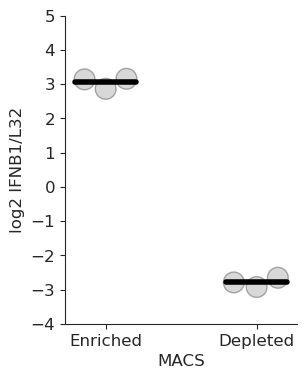

In [7]:
data = pd.read_csv(os.path.join(dataDirectory, 'PA_lib_MACS.csv')).pivot_table(index=['MACS','replicate'], columns = 'target', aggfunc="mean", values='Cq').reset_index()
data['log2_IFNB1/L32'] = data.L32 - data['IFN-B']



fig, ax = plt.subplots(1,1, figsize=(3,4))
order = ['Enriched','Depleted']

sns.swarmplot(y='log2_IFNB1/L32', x='MACS', data=data, palette = ['0.5'], edgecolor='0',        
                dodge=False, linewidth=1, s=15,   zorder=5, order=order, ax=ax, alpha=0.3)

sns.despine()
a = plt.ylabel('log2 IFNB1/L32')
tstat, pval = stats.ttest_ind(data[data.MACS == 'Enriched']['log2_IFNB1/L32'], 
                                  data[data.MACS == 'Depleted']['log2_IFNB1/L32'], alternative='greater')
print(pval)

offset = 0
for position, MACS in enumerate(order):
    y = data[data.MACS == MACS]['log2_IFNB1/L32'].mean()
    plt.plot([position-0.2, position+0.2], [y, y], lw=4, c='k', zorder=9)

plt.ylim(-4,5)

plt.savefig(os.path.join(figureDirectory, 'PA_lib_MACS.pdf'), bbox_inches="tight")

U16A and U20A in PB1 of varying templates without complementation

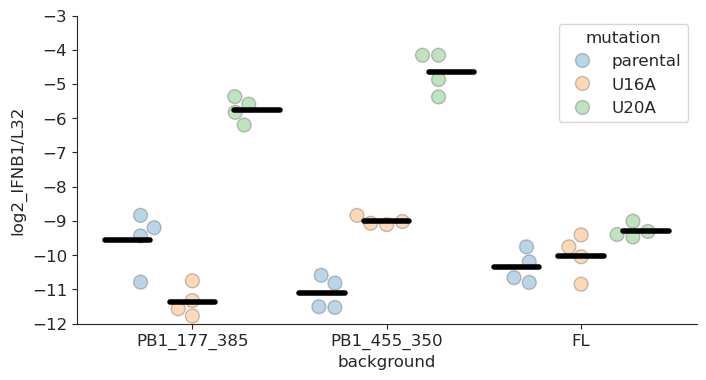

In [9]:
fig, ax = plt.subplots(1,1, figsize=(8,4))
hue_order = ['parental','U16A','U20A']
data = pd.read_csv(os.path.join(dataDirectory, 'PB1_polyuracil_conf.csv'))
order = ['PB1_177_385', 'PB1_455_350','FL']
data['log2_IFNB1/L32'] = data.L32 - data.IFN
sns.swarmplot(y='log2_IFNB1/L32', x='background', hue='mutation',hue_order=hue_order, data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()



plt.ylim (-12,-3)
pvals = []
for position, strain in enumerate(order):
    curr = data[data['background'] == strain]
    bar = 1/len(hue_order)
    for add, mutation in enumerate(hue_order):
        if mutation!= 'parental':
            tstat, pval = stats.ttest_ind(curr[curr.mutation == 'parental']['log2_IFNB1/L32'], curr[curr.mutation == mutation]['log2_IFNB1/L32'])
            pvals += [pval]
        y = data[(data.background == strain) & (data.mutation == mutation)]['log2_IFNB1/L32'].mean()
        plt.plot([0.5+position-(len(hue_order)-add)*bar+0.05,0.5+position-(len(hue_order)-add)*bar + bar -0.05], [y, y], lw=4, c='k', zorder=9)
plt.savefig(os.path.join(figureDirectory, 'PB1_SNP.pdf'), bbox_inches="tight")

In [9]:
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

array([1.17304472e-02, 3.35976704e-04, 3.35976704e-04, 1.62772443e-05,
       4.16850684e-01, 9.36776480e-03])

0.0001697229545086452


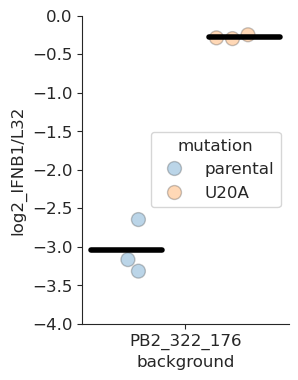

In [12]:
fig, ax = plt.subplots(1,1, figsize=(2.67,4))
hue_order = ['parental','U20A']
data = pd.read_csv(os.path.join(dataDirectory, 'PB2_polyuracil_conf.csv'))
order = ['PB2_322_176']
data['log2_IFNB1/L32'] = data.L32 - data.IFN
sns.swarmplot(y='log2_IFNB1/L32', x='background', hue='mutation',hue_order=hue_order, data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()
tstat, pval = stats.ttest_ind(data[data.mutation == 'parental']['log2_IFNB1/L32'], data[data.mutation == 'U20A']['log2_IFNB1/L32'])

plt.ylim (-4,0)

for position, strain in enumerate(order):
    curr = data[data['background'] == strain]
    bar = 1/len(hue_order)
    for add, mutation in enumerate(hue_order):
        y = data[(data.background == strain) & (data.mutation == mutation)]['log2_IFNB1/L32'].mean()
        plt.plot([0.5+position-(len(hue_order)-add)*bar+0.1,0.5+position-(len(hue_order)-add)*bar + bar -0.1], [y, y], lw=4, c='k', zorder=9)
plt.savefig(os.path.join(figureDirectory, 'PB2_SNP.pdf'), bbox_inches="tight")
print(pval)

RIG-I dependence

array([2.22164791e-02, 3.38733490e-05])

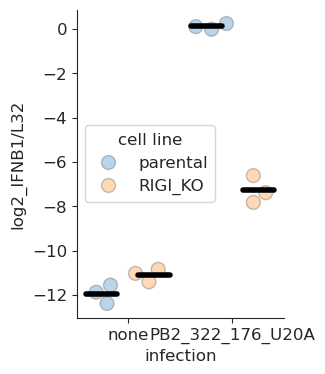

In [16]:
fig, ax = plt.subplots(1,1, figsize=(2.67,4))
hue_order = ['parental','RIGI_KO']
data = pd.read_csv(os.path.join(dataDirectory, 'RIG_I_U20A.csv'))
order = ['none','PB2_322_176_U20A']
data['log2_IFNB1/L32'] = data.L32 - data.IFN
sns.swarmplot(y='log2_IFNB1/L32', x='infection', hue='cell line',hue_order=hue_order, data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()
pvals = []

for position, infection in enumerate(order):
    curr = data[data['infection'] == infection]
    bar = 1/len(hue_order)
    tstat, pval = stats.ttest_ind(curr[curr['cell line'] == 'parental']['log2_IFNB1/L32'], curr[curr['cell line'] == 'RIGI_KO']['log2_IFNB1/L32'])
    pvals += [pval/2]
    for add, cell in enumerate(hue_order):
        y = curr[(curr['cell line'] == cell)]['log2_IFNB1/L32'].mean()
        plt.plot([0.5+position-(len(hue_order)-add)*bar+0.1,0.5+position-(len(hue_order)-add)*bar + bar -0.1], [y, y], lw=4, c='k', zorder=9)
plt.savefig(os.path.join(figureDirectory, 'RIGI.pdf'), bbox_inches="tight")
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

                     Multiple Comparison of Means - Tukey HSD, FWER=0.05                     
          group1                     group2           meandiff p-adj   lower    upper  reject
---------------------------------------------------------------------------------------------
      PB2_322_176_U20A_BAL     PB2_322_176_U20A_CYCLO   9.4867    0.0    8.432 10.5413   True
      PB2_322_176_U20A_BAL PB2_322_176_U20A_CYCLO_BAL     4.58    0.0   3.5254  5.6346   True
      PB2_322_176_U20A_BAL       PB2_322_176_U20A_LEP     4.77    0.0   3.7154  5.8246   True
      PB2_322_176_U20A_BAL      PB2_322_176_U20A_none   6.7667    0.0    5.712  7.8213   True
      PB2_322_176_U20A_BAL                  none_none    -4.65    0.0  -5.7046 -3.5954   True
    PB2_322_176_U20A_CYCLO PB2_322_176_U20A_CYCLO_BAL  -4.9067    0.0  -5.9613  -3.852   True
    PB2_322_176_U20A_CYCLO       PB2_322_176_U20A_LEP  -4.7167    0.0  -5.7713  -3.662   True
    PB2_322_176_U20A_CYCLO      PB2_322_176_U20A_none    -2.

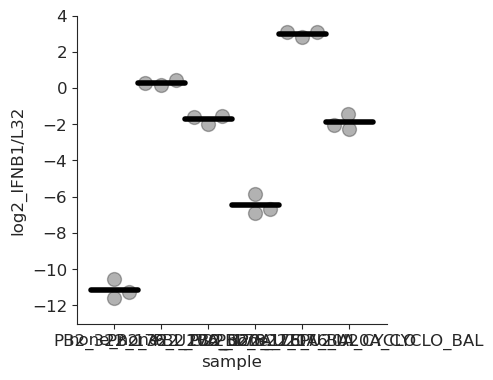

In [17]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
order = ['none_none','PB2_322_176_U20A_none','PB2_322_176_U20A_LEP','PB2_322_176_U20A_BAL','PB2_322_176_U20A_CYCLO','PB2_322_176_U20A_CYCLO_BAL']
data = pd.read_csv(os.path.join(dataDirectory, 'U20A_inhibit.csv'))
data['sample'] = data.infection + '_' + data.treatment
data['log2_IFNB1/L32'] = data.L32 - data.IFN
sns.swarmplot(y='log2_IFNB1/L32', x='sample',  data=data, color='k',        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()

plt.ylim(-13,4)
for position, infection in enumerate(order):
    y = data[data['sample'] == infection]['log2_IFNB1/L32'].mean()
    plt.plot([position-0.5,0.5+position], [y, y], lw=4, c='k', zorder=9)

stat, pval = scipy.stats.f_oneway(*[data[data['sample'] == category]['log2_IFNB1/L32'] for category in set(data['sample'])])
if pval < 0.05:
    tukey = pairwise_tukeyhsd(endog=data['log2_IFNB1/L32'],
                              groups=data['sample'],
                              alpha=0.05)
    print(tukey)
plt.savefig(os.path.join(figureDirectory, 'inhibitor.pdf'), bbox_inches="tight")

ANOVA probably not ideal for manuscript, but useful here to make sure all looks good., here are one-tailed t-tests against reduction within each group.

In [17]:
graph = data[data.infection == 'PB2_322_176_U20A']
pvals = []
pvals += [stats.ttest_ind(graph[graph.treatment == 'none']['log2_IFNB1/L32'], graph[graph.treatment == 'LEP']['log2_IFNB1/L32'], alternative = 'greater')[1]]
pvals += [stats.ttest_ind(graph[graph.treatment == 'none']['log2_IFNB1/L32'], graph[graph.treatment == 'BAL']['log2_IFNB1/L32'], alternative = 'greater')[1]]
pvals += [stats.ttest_ind(graph[graph.treatment == 'CYCLO']['log2_IFNB1/L32'], graph[graph.treatment == 'CYCLO_BAL']['log2_IFNB1/L32'], alternative = 'greater')[1]]



In [18]:
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

array([1.01198975e-04, 3.66614344e-05, 3.66614344e-05])

                     Multiple Comparison of Means - Tukey HSD, FWER=0.05                      
          group1                     group2           meandiff p-adj   lower    upper   reject
----------------------------------------------------------------------------------------------
      PB2_322_176_U20A_BAL     PB2_322_176_U20A_CYCLO   2.5967 0.0001    1.364   3.8293   True
      PB2_322_176_U20A_BAL PB2_322_176_U20A_CYCLO_BAL     0.62 0.5621  -0.6126   1.8526  False
      PB2_322_176_U20A_BAL       PB2_322_176_U20A_LEP   2.6133 0.0001   1.3807    3.846   True
      PB2_322_176_U20A_BAL      PB2_322_176_U20A_none   1.6267 0.0082    0.394   2.8593   True
      PB2_322_176_U20A_BAL                  none_none -12.1167    0.0 -13.3493  -10.884   True
    PB2_322_176_U20A_CYCLO PB2_322_176_U20A_CYCLO_BAL  -1.9767 0.0017  -3.2093   -0.744   True
    PB2_322_176_U20A_CYCLO       PB2_322_176_U20A_LEP   0.0167    1.0   -1.216   1.2493  False
    PB2_322_176_U20A_CYCLO      PB2_322_176_U20A_n

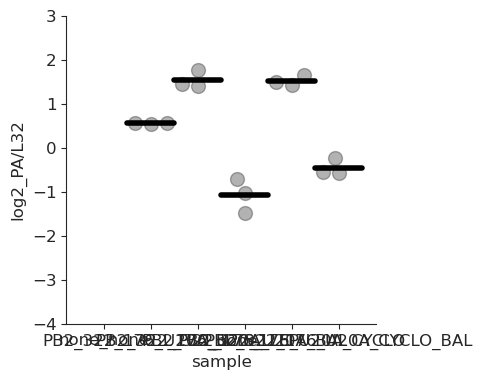

In [19]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
order = ['none_none','PB2_322_176_U20A_none','PB2_322_176_U20A_LEP','PB2_322_176_U20A_BAL','PB2_322_176_U20A_CYCLO','PB2_322_176_U20A_CYCLO_BAL']
data = pd.read_csv(os.path.join(dataDirectory, 'U20A_inhibit.csv'))
data['sample'] = data.infection + '_' + data.treatment
data['log2_PA/L32'] = data.L32 - data.PA
sns.swarmplot(y='log2_PA/L32', x='sample',  data=data, color='k',        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()

plt.ylim(-4,3)
for position, infection in enumerate(order):
    y = data[data['sample'] == infection]['log2_PA/L32'].mean()
    plt.plot([position-0.5,0.5+position], [y, y], lw=4, c='k', zorder=9)

stat, pval = scipy.stats.f_oneway(*[data[data['sample'] == category]['log2_PA/L32'] for category in set(data['sample'])])
if pval < 0.05:
    tukey = pairwise_tukeyhsd(endog=data['log2_PA/L32'],
                              groups=data['sample'],
                              alpha=0.05)
    print(tukey)
plt.savefig(os.path.join(figureDirectory, 'inhibitor_PA.pdf'), bbox_inches="tight")

In [21]:
graph = data[data.infection == 'PB2_322_176_U20A']
pvals = []
pvals += [stats.ttest_ind(graph[graph.treatment == 'none']['log2_PA/L32'], graph[graph.treatment == 'LEP']['log2_PA/L32'], alternative = 'greater')[1]]
pvals += [stats.ttest_ind(graph[graph.treatment == 'none']['log2_PA/L32'], graph[graph.treatment == 'BAL']['log2_PA/L32'], alternative = 'greater')[1]]
pvals += [stats.ttest_ind(graph[graph.treatment == 'CYCLO']['log2_PA/L32'], graph[graph.treatment == 'CYCLO_BAL']['log2_PA/L32'], alternative = 'greater')[1]]


In [22]:
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

array([9.99417605e-01, 1.42515933e-03, 1.58159856e-04])

RNA content supernatant of various mutants

array([0.01775023, 0.02555896, 0.03142929])

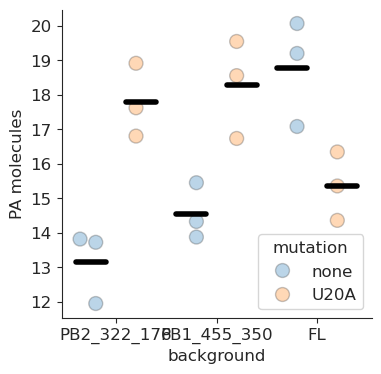

In [20]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
order = ['PB2_322_176','PB1_455_350','FL']
hue_order = ['none','U20A']
data = pd.read_csv(os.path.join(dataDirectory, 'supernatant.csv'))
#correct for 0.71µl supernatant
data['PA molecules'] = np.log2((2**data['PA molecules'])/0.71)

sns.swarmplot(y='PA molecules', x='background', hue='mutation',hue_order=hue_order, data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()

pvals = []
for position, infection in enumerate(order):
    curr = data[data['background'] == infection]
    bar = 1/len(hue_order)
    tstat, pval = stats.ttest_ind(curr[curr.mutation == 'none']['PA molecules'], curr[curr.mutation == 'U20A']['PA molecules'])
    pvals +=[pval]

    for add, mutation in enumerate(hue_order):
        y = curr[(curr['mutation'] == mutation)]['PA molecules'].mean()
        plt.plot([0.5+position-(len(hue_order)-add)*bar+0.1,0.5+position-(len(hue_order)-add)*bar + bar -0.1], [y, y], lw=4, c='k', zorder=9)
plt.savefig(os.path.join(figureDirectory, 'supernatant.pdf'), bbox_inches="tight")
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower  upper  reject
--------------------------------------------------
   427     87   3.2222    0.0 2.6421 3.8024   True
   427   none   4.2361    0.0  3.656 4.8163   True
    87   none   1.0139 0.0042 0.4337  1.594   True
--------------------------------------------------


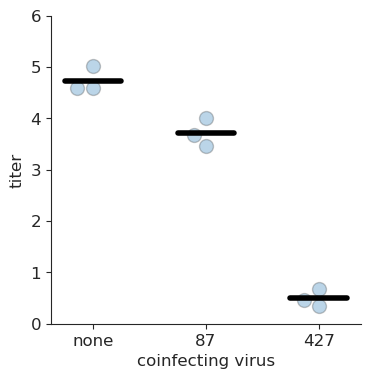

In [23]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
order = ['none','87','427']
hue_order = ['none','U20A']
data = pd.read_csv(os.path.join('Results','titers', 'coinfection_none.csv'))
data['titer'] = np.log10(data.titer)

sns.swarmplot(y='titer', x='coinfecting virus',  data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()

for position, infection in enumerate(order):
    curr = data[data['coinfecting virus'] == infection]
    bar = 0.25
    y = curr['titer'].mean()
    plt.plot([position-bar,position+ bar], [y, y], lw=4, c='k', zorder=9)
plt.ylim(0,6)
plt.savefig(os.path.join(figureDirectory, 'titer.pdf'), bbox_inches="tight")

stat, pval = scipy.stats.f_oneway(*[data[data['coinfecting virus'] == category]['titer'] for category in order])
if pval < 0.05:
    tukey = pairwise_tukeyhsd(endog=data['titer'],
                              groups=data['coinfecting virus'],
                              alpha=0.05)
print(tukey)

array([0.00643256, 0.00643256])

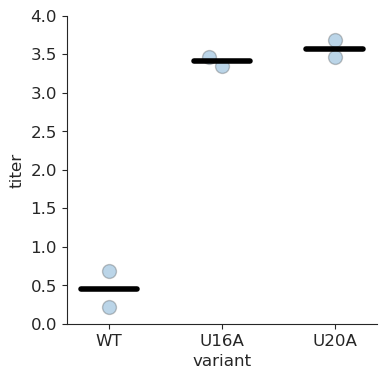

In [25]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
order = ['WT','U16A','U20A']
data = pd.read_csv(os.path.join('Results','titers', 'RG_rescue.csv'))
data['titer'] = np.log10(data.titer)

sns.swarmplot(y='titer', x='variant',  data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()

for position, infection in enumerate(order):
    curr = data[data['variant'] == infection]
    bar = 0.25
    y = curr['titer'].mean()
    plt.plot([position-bar,position+ bar], [y, y], lw=4, c='k', zorder=9)
plt.ylim(0,4)
plt.savefig(os.path.join(figureDirectory, 'RG_titer.pdf'), bbox_inches="tight")

pvals = []

tstat, pval = stats.ttest_ind(data[data.variant == 'WT']['titer'], data[data.variant == 'U16A']['titer'])
pvals += [pval]
tstat, pval = stats.ttest_ind(data[data.variant == 'WT']['titer'], data[data.variant == 'U20A']['titer'])
pvals += [pval]
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

array([0.0353175])

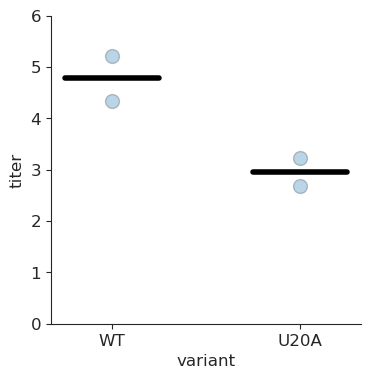

In [27]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
order = ['WT','U20A']
data = pd.read_csv(os.path.join('Results','titers', 'RG_rescue_FL.csv'))
data['titer'] = np.log10(data.titer)

sns.swarmplot(y='titer', x='variant',  data=data,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=order, ax=ax, alpha=0.3)
sns.despine()

for position, infection in enumerate(order):
    curr = data[data['variant'] == infection]
    bar = 0.25
    y = curr['titer'].mean()
    plt.plot([position-bar,position+ bar], [y, y], lw=4, c='k', zorder=9)
plt.ylim(0,6)
plt.savefig(os.path.join(figureDirectory, 'RG_FL_titer.pdf'), bbox_inches="tight")

pvals = []
tstat, pval = stats.ttest_ind(data[data.variant == 'WT']['titer'], data[data.variant == 'U20A']['titer'])
pvals += [pval/2]
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

In [28]:
data.to_csv('delete.csv')